# Op-Amp Problems 5.1–5.2: The Inverting Amplifier in SymPy

**Source:** J. W. Nilsson and S. A. Riedel, *Electric Circuits*. Hoboken, NJ, USA: Pearson, Probs. 5.1–5.2,
Fig. P5.1. *(Add your edition and year for a full IEEE citation.)*

The circuit: $v_s = 2$ V through $R_1 = 4$ kΩ into the inverting input; $R_f = 12$ kΩ feedback;
non-inverting input grounded; ±15 V supplies; 6 kΩ load. Module:
[`dgs/opamp_inverting.py`](../dgs/opamp_inverting.py)

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np
import sympy as sp
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
sp.init_printing()
from dgs.opamp_inverting import (
    ideal_solution, finite_gain_solution, output_voltage, is_saturated, linear_input_range,
    output_current, PROBLEM_5_2_SOURCES,
)

## 5.1 (a)–(c): terminals and the two ideal rules

| terminal | symbol |
|---|---|
| inverting input | $v_n$ (−) |
| non-inverting input | $v_p$ (+), grounded here |
| output | $v_o$ |
| positive supply | $+V_{CC} = +15$ V |
| negative supply | $-V_{CC} = -15$ V |

- **(b)** $i_n = 0$, because an ideal op amp has **infinite input resistance**.
- **(c)** $v_p - v_n = 0$ (the **virtual short**). This holds only *with negative feedback* and *while
  the output is not saturated*.

## The gap the book skips: where the virtual short comes from

Model the op amp as $v_o = A(v_p - v_n)$ with finite gain $A$ and solve KCL at $v_n$. Then let $A\to\infty$:

In [2]:
vo_A, vo_inf, vn_A, (vs, R1, Rf, A) = finite_gain_solution()
display(Math(r"v_o(A) = " + sp.latex(vo_A)))
display(Math(r"v_n(A) = " + sp.latex(vn_A) + r"\;\xrightarrow{A\to\infty}\; " + sp.latex(sp.limit(vn_A, A, sp.oo))))
display(Math(r"\lim_{A\to\infty} v_o = " + sp.latex(vo_inf)))
for Av in (1e2, 1e4, 1e6):
    print(f"A = {Av:8.0e}: v_o = {float(vo_A.subs({vs: 2, R1: 4e3, Rf: 12e3, A: Av})):.6f} V,  v_n = {float(vn_A.subs({vs: 2, R1: 4e3, Rf: 12e3, A: Av}))*1e3:.4f} mV")

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

A =    1e+02: v_o = -5.769231 V,  v_n = 57.6923 mV
A =    1e+04: v_o = -5.997601 V,  v_n = 0.5998 mV
A =    1e+06: v_o = -5.999976 V,  v_n = 0.0060 mV


As the gain grows, $v_n$ is driven to 0 V (the virtual short) and $v_o \to -(R_f/R_1)v_s$. A real
op amp with $A \approx 10^5$ is already within 0.004% of the ideal answer.

## 5.1 (d)

KCL at $v_n$ with $i_n = 0$ and $v_n = v_p = 0$: $\;\dfrac{2 - 0}{4\text{ k}} + \dfrac{v_o - 0}{12\text{ k}} = 0$.

In [3]:
vo_ideal, _ = ideal_solution()
display(Math(r"v_o = " + sp.latex(vo_ideal)))
print(f"v_o = {float(output_voltage(2.0)):.2f} V   (gain −12k/4k = −3)")
print(f"op-amp output current = load + feedback = {float(output_current(2.0))*1e3:.2f} mA")

<IPython.core.display.Math object>

v_o = -6.00 V   (gain −12k/4k = −3)
op-amp output current = load + feedback = -1.50 mA


## 5.2: other sources, and saturation

The output can't go beyond the supplies, so $v_o = \text{clip}(-3v_s, -15, +15)$:

,v_s (V),−3·v_s (V),v_o (V),saturated?
0,-6.00,18.00,15.00,True
1,-3.50,10.50,10.50,False
2,-1.25,3.75,3.75,False
3,2.40,-7.20,-7.20,False
4,4.50,-13.50,-13.50,False
5,5.40,-16.20,-15.00,True


(b) linear (no saturation) for -5.0 V ≤ v_s ≤ 5.0 V


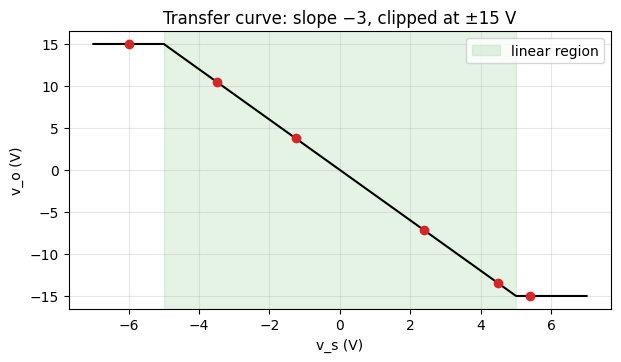

In [4]:
vo = output_voltage(PROBLEM_5_2_SOURCES)
display(pd.DataFrame({"v_s (V)": PROBLEM_5_2_SOURCES, "−3·v_s (V)": [-3*v for v in PROBLEM_5_2_SOURCES],
                      "v_o (V)": vo, "saturated?": is_saturated(PROBLEM_5_2_SOURCES)}))
lo, hi = linear_input_range()
print(f"(b) linear (no saturation) for {lo:.1f} V ≤ v_s ≤ {hi:.1f} V")
vv = np.linspace(-7, 7, 400)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(vv, output_voltage(vv), "k"); ax.plot(PROBLEM_5_2_SOURCES, vo, "o", color="C3")
ax.axvspan(lo, hi, color="C2", alpha=0.12, label="linear region")
ax.set(xlabel="v_s (V)", ylabel="v_o (V)", title="Transfer curve: slope −3, clipped at ±15 V"); ax.legend(); ax.grid(alpha=0.3); plt.show()

The two saturated points ($v_s = -6$ V and $5.4$ V) are where the linear formula would ask for
+18 V and −16.2 V, more than the supplies can provide. Inside $|v_s| \le 5$ V, every answer is just $-3v_s$.